# CCA (Complete Case Analysis)

-  Analyzing only those observations for which there is information in all of the variables in the dataset .

### Assumption:
- Missing completely at random (MCAR)

### Pros:
- Easy to implement / no data manipulation needed
- same distribution as before 

### Cons:
- When using model in production, model will not know how to handle missing data . 

In [6]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [7]:
df= pd.read_csv('../../data/data_science_job.csv')

In [8]:
df.sample(5)

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
2568,29842,city_103,0.920,Male,No relevent experience,no_enrollment,Graduate,STEM,5.0,NaN,NaN,86.0,1.0
4720,1889,city_76,0.698,Male,Has relevent experience,no_enrollment,Masters,STEM,7.0,10000+,Pvt Ltd,48.0,0.0
13780,6832,city_64,0.666,NaN,Has relevent experience,no_enrollment,Graduate,STEM,6.0,50-99,Funded Startup,29.0,0.0
15990,21748,city_138,0.836,NaN,No relevent experience,no_enrollment,Primary School,NaN,1.0,NaN,NaN,9.0,0.0
7176,4584,city_176,0.764,NaN,No relevent experience,Full time course,Graduate,STEM,2.0,NaN,NaN,58.0,1.0


In [9]:
df.isnull().sum()

enrollee_id                  0
city                         0
city_development_index     479
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
training_hours             766
target                       0
dtype: int64

In [10]:
df.isnull().mean()*100

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

In [11]:
df.shape

(19158, 13)

In [12]:
cols = [var for var in df.columns if df[var].isnull().mean() < 0.05 and df[var].isnull().mean() > 0]
cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [13]:
df[cols].sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
18105,0.624,Part time course,Masters,1.0,53.0
17888,0.920,no_enrollment,Masters,0.0,59.0
7654,0.910,no_enrollment,Masters,15.0,40.0
10079,0.920,Full time course,Graduate,2.0,19.0
13862,0.920,Full time course,Graduate,NaN,20.0


In [14]:
len(df[cols].dropna())/len(df)

0.8968577095730244

In [15]:
new_df= df[cols].dropna()
df.shape, new_df.shape

((19158, 13), (17182, 5))

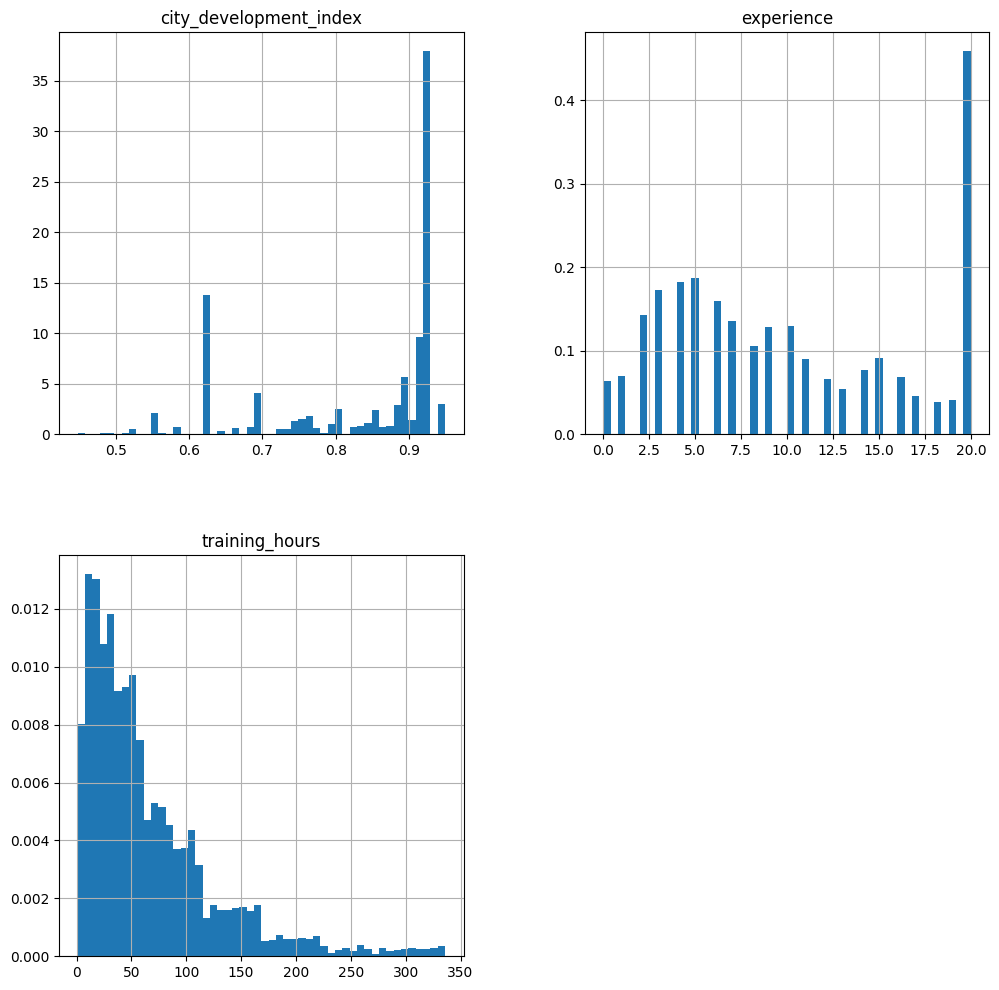

In [16]:
new_df.hist(bins=50, density=True, figsize=(12, 12))
plt.show()

<Axes: xlabel='training_hours', ylabel='Density'>

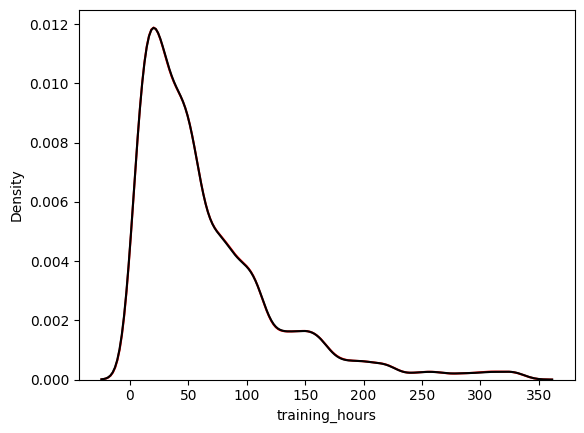

In [19]:
import seaborn as sns 

fig = plt.figure()
ax = fig.add_subplot(111)

# original data
# df['training_hours'].hist(bins=50, ax=ax, density=True, color='red')
sns.kdeplot(df['training_hours'], color='red')
sns.kdeplot(new_df['training_hours'], color='black')


# data after cca, the argument alpha makes the color transparent, so we can
# see the overlay of the 2 distributions
# new_df['training_hours'].hist(bins=50, ax=ax, color='green', density=True, alpha=0.8)

<Axes: >

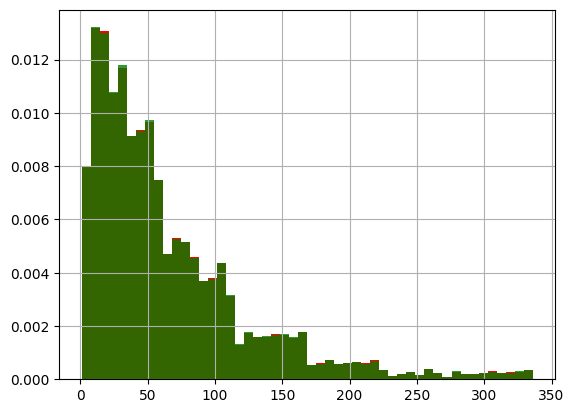

In [20]:
import seaborn as sns 

fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['training_hours'].hist(bins=50, ax=ax, density=True, color='red')



# data after cca, the argument alpha makes the color transparent, so we can
# see the overlay of the 2 distributions
new_df['training_hours'].hist(bins=50, ax=ax, color='green', density=True, alpha=0.8)

<Axes: >

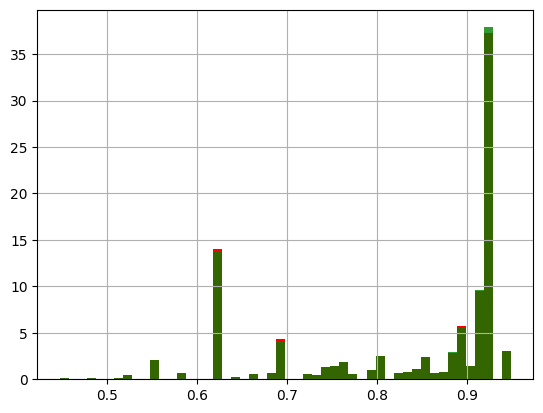

In [21]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['city_development_index'].hist(bins=50, ax=ax, density=True, color='red')

# data after cca, the argument alpha makes the color transparent, so we can
# see the overlay of the 2 distributions
new_df['city_development_index'].hist(bins=50, ax=ax, color='green', density=True, alpha=0.8)

<Axes: ylabel='Density'>

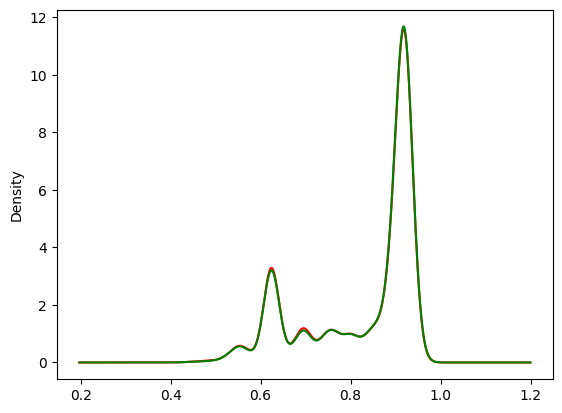

In [22]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['city_development_index'].plot.density(color='red')

# data after cca
new_df['city_development_index'].plot.density(color='green')

<Axes: >

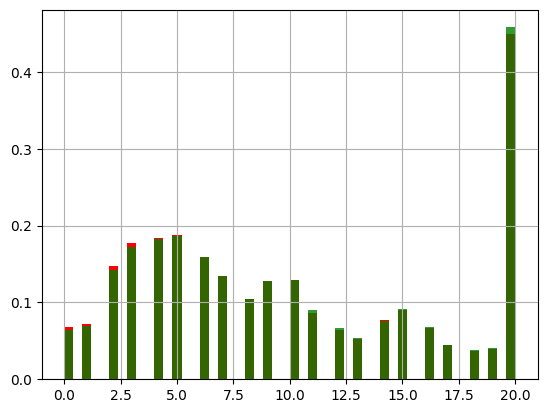

In [23]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['experience'].hist(bins=50, ax=ax, density=True, color='red')

# data after cca, the argument alpha makes the color transparent, so we can
# see the overlay of the 2 distributions
new_df['experience'].hist(bins=50, ax=ax, color='green', density=True, alpha=0.8)

<Axes: ylabel='Density'>

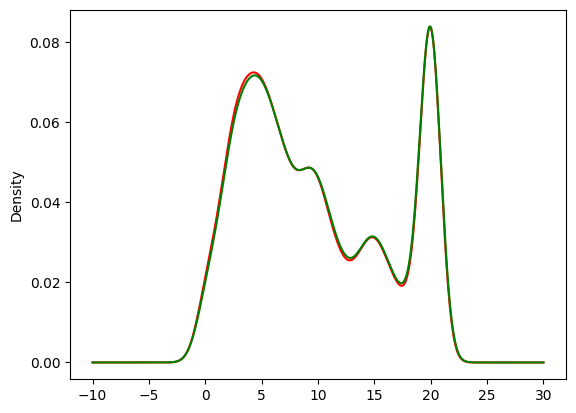

In [24]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original data
df['experience'].plot.density(color='red')

# data after cca
new_df['experience'].plot.density(color='green')

In [26]:
# To check the ratio of each categories remains the same before and after cca , so that we know the value was MCAR.
temp = pd.concat([
            # percentage of observations per category, original data
            df['enrolled_university'].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df['enrolled_university'].value_counts() / len(new_df)
        ],
        axis=1)

# add column names
temp.columns = ['original', 'cca']

temp

,original,cca
enrolled_university,,
no_enrollment,0.721213,0.735188
Full time course,0.196106,0.200733
Part time course,0.062533,0.064079


In [27]:
temp = pd.concat([
            # percentage of observations per category, original data
            df['education_level'].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df['education_level'].value_counts() / len(new_df)
        ],
        axis=1)

# add column names
temp.columns = ['original', 'cca']

temp

,original,cca
education_level,,
Graduate,0.605387,0.619835
Masters,0.227633,0.234082
High School,0.105282,0.107380
Phd,0.021610,0.022116
Primary School,0.016077,0.016587
